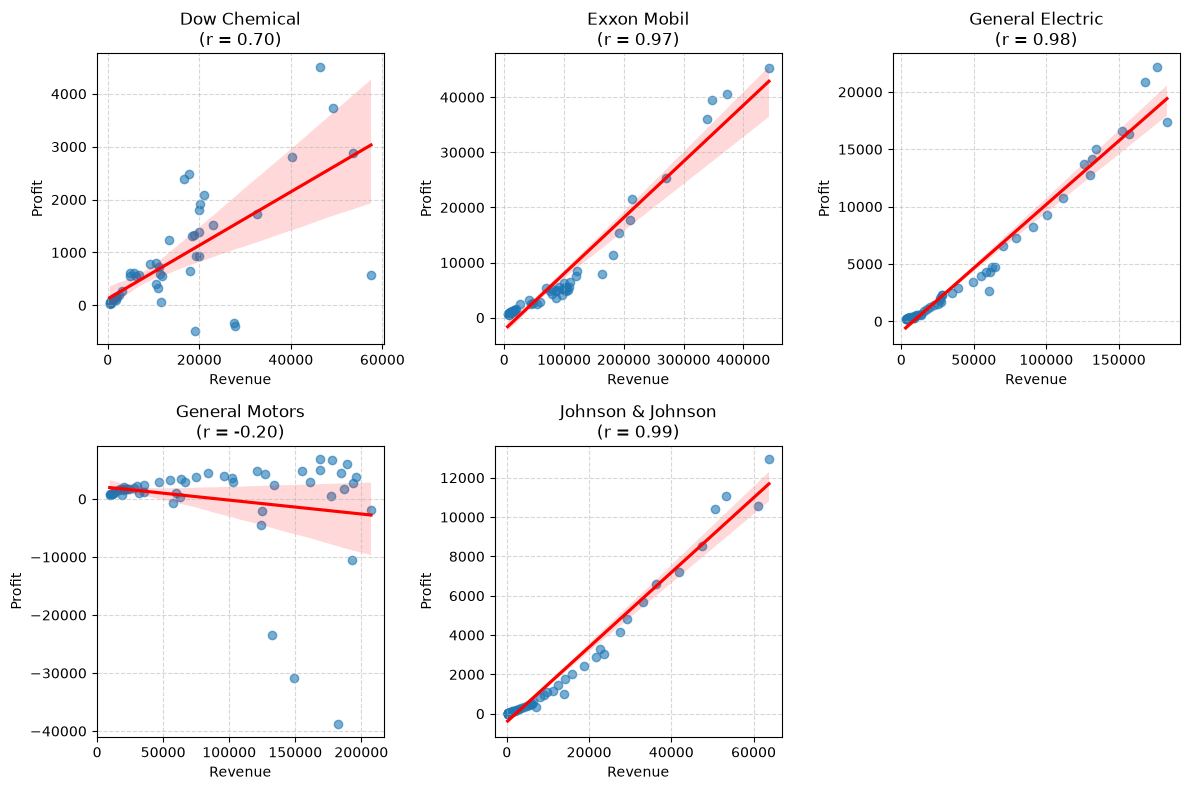

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

plt.figure(figsize=(12, 8))
for i, (company, group) in enumerate(df.groupby('Company'), 1):
    plt.subplot(2, 3, i)
    sns.regplot(
        data=group, 
        x='Revenue (in millions)', 
        y='Profit (in millions)', 
        scatter_kws={'alpha': 0.6}, 
        line_kws={'color': 'red'}
    )
    
    # คำนวณค่า r ของบริษัทนั้นๆ
    r, _ = pearsonr(group['Revenue (in millions)'], group['Profit (in millions)'])
    
    plt.title(f'{company}\n(r = {r:.2f})')
    plt.xlabel('Revenue')
    plt.ylabel('Profit')
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [5]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

df = pd.read_excel(r"d:\python1\No.1_Python.xlsx")

models, test_sets, rows = {}, {}, []

for company, g in df.groupby("Company"):
    X = g[["Revenue (in millions)"]]
    y = g["Profit (in millions)"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    rf = RandomForestRegressor(n_estimators=200, random_state=42)
    rf.fit(X_train, y_train)               # ฝึกด้วยชุด train เท่านั้น

    pred = rf.predict(X_train)
    rows.append({
        "Company": company,
        "n_train": len(y_train),
        "R²": r2_score(y_train, pred),
        "RMSE": np.sqrt(mean_squared_error(y_train, pred)),
        "MAE": mean_absolute_error(y_train, pred),
    })

    models[company] = rf                   # เก็บโมเดล
    test_sets[company] = (X_test, y_test)  # เก็บชุด test ไว้ให้ไฟล์ test ใช้

print("=== ผล TRAIN ===")
print(pd.DataFrame(rows).round(4).to_string(index=False))

joblib.dump(models, "models.pkl")
joblib.dump(test_sets, "test_sets.pkl")

=== ผล TRAIN ===
          Company  n_train     R²      RMSE       MAE
     Dow Chemical       44 0.9313  260.4624  149.1017
      Exxon Mobil       44 0.9962  635.5851  380.5824
 General Electric       44 0.9951  404.9266  203.0814
   General Motors       44 0.8008 3938.6383 1998.6898
Johnson & Johnson       44 0.9965  189.0390   90.5538


['test_sets.pkl']

In [6]:
import pandas as pd
import numpy as np
import joblib
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

models = joblib.load("models.pkl")
test_sets = joblib.load("test_sets.pkl")

rows = []
for company, rf in models.items():
    X_test, y_test = test_sets[company]
    pred = rf.predict(X_test)
    rows.append({
        "Company": company,
        "n_test": len(y_test),
        "R²": r2_score(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
    })

print("=== ผล TEST ===")
print(pd.DataFrame(rows).round(4).to_string(index=False))

=== ผล TEST ===
          Company  n_test      R²      RMSE       MAE
     Dow Chemical      11  0.6592  650.8265  410.1730
      Exxon Mobil      11  0.9712 1895.6411 1238.1643
 General Electric      11  0.9885  703.7967  464.5254
   General Motors      11 -1.7665 4359.3979 2486.4191
Johnson & Johnson      11  0.9852  421.8832  239.2286


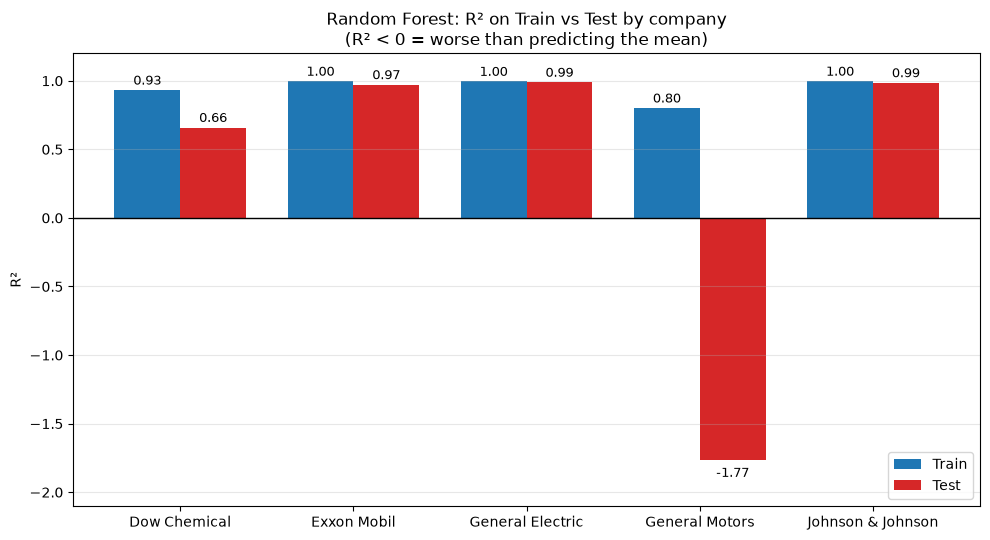

                    Train    Test
Company                          
Dow Chemical       0.9313  0.6592
Exxon Mobil        0.9962  0.9712
General Electric   0.9951  0.9885
General Motors     0.8008 -1.7665
Johnson & Johnson  0.9965  0.9852


In [7]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

df = pd.read_excel(r"d:\python1\No.1_Python.xlsx")

rows = []
for company, g in df.groupby("Company"):
    X = g[["Revenue (in millions)"]]
    y = g["Profit (in millions)"]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    rf = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_train, y_train)
    rows.append({
        "Company": company,
        "Train": r2_score(y_train, rf.predict(X_train)),
        "Test": r2_score(y_test, rf.predict(X_test)),
    })
res = pd.DataFrame(rows).set_index("Company")

# ---- วาดกราฟ ----
fig, ax = plt.subplots(figsize=(10, 5.5))
x = range(len(res))
w = 0.38
b1 = ax.bar([i - w / 2 for i in x], res["Train"], w, label="Train", color="tab:blue")
b2 = ax.bar([i + w / 2 for i in x], res["Test"], w, label="Test", color="tab:red")

for bars in (b1, b2):
    for b in bars:
        h = b.get_height()
        ax.annotate(f"{h:.2f}", (b.get_x() + b.get_width() / 2, h),
                    xytext=(0, 4 if h >= 0 else -12), textcoords="offset points",
                    ha="center", fontsize=9)

ax.axhline(0, color="black", lw=1)
ax.set_xticks(list(x))
ax.set_xticklabels(res.index)
ax.set_ylabel("R²")
ax.set_ylim(-2.1, 1.2)
ax.set_title("Random Forest: R² on Train vs Test by company\n(R² < 0 = worse than predicting the mean)")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("fig_train_vs_test_r2.png", dpi=150)
plt.show()
print(res.round(4))

In [8]:
import pandas as pd

# 1. กำหนด Path ของไฟล์
excel_file = r"d:\python1\No.1_Python.xlsx"

# 2. อ่านไฟล์ Excel ผ่าน pd.ExcelFile เพื่อเก็บตัวแปร xls
xls = pd.ExcelFile(excel_file)

# 3. แสดงรายชื่อ Sheet ทั้งหมดที่มีในไฟล์
print("Sheet names:", xls.sheet_names)

# 4. วนลูปอ่านข้อมูลของแต่ละ Sheet
for sheet in xls.sheet_names:
    df = pd.read_excel(xls, sheet_name=sheet)
    print(f"\n--- Sheet: {sheet} ---")
    print(df.head())
    print(df.info())

Sheet names: ['Sheet1']

--- Sheet: Sheet1 ---
   Year  Rank            Company  Revenue (in millions)  Profit (in millions)
0  1955     1     General Motors                 9823.5                 806.0
1  1955     2        Exxon Mobil                 5661.4                 584.8
2  1955     4   General Electric                 2959.1                 212.6
3  1955    69       Dow Chemical                  428.3                  33.4
4  1955   159  Johnson & Johnson                  200.9                   9.5
<class 'pandas.DataFrame'>
RangeIndex: 275 entries, 0 to 274
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Year                   275 non-null    int64  
 1   Rank                   275 non-null    int64  
 2   Company                275 non-null    str    
 3   Revenue (in millions)  275 non-null    float64
 4   Profit (in millions)   275 non-null    float64
dtypes: float64(2), int64(2)

In [9]:
# Analyze data around 2007-2010 (Hamburger Crisis) and full dataset
excel_file = r"d:\python1\No.1_Python.xlsx"
print("Years range:", df['Year'].min(), "to", df['Year'].max())
print("Companies included:", df['Company'].unique())

# Filter for Hamburger Crisis period (e.g. 2006 to 2011)
crisis_df = df[(df['Year'] >= 2006) & (df['Year'] <= 2011)]
print("\nCrisis Period Data (2006-2011):")
print(crisis_df.pivot(index='Year', columns='Company', values=['Revenue (in millions)', 'Profit (in millions)']))

Years range: 1955 to 2009
Companies included: <StringArray>
[   'General Motors',       'Exxon Mobil',  'General Electric',
      'Dow Chemical', 'Johnson & Johnson']
Length: 5, dtype: str

Crisis Period Data (2006-2011):
        Revenue (in millions)                                              \
Company          Dow Chemical Exxon Mobil General Electric General Motors   
Year                                                                        
2006                  46307.0    339938.0         157153.0       192604.0   
2007                  49124.0    347254.0         168307.0       207349.0   
2008                  53513.0    372824.0         176656.0       182347.0   
2009                  57514.0    442851.0         183207.0       148979.0   

                          Profit (in millions)                               \
Company Johnson & Johnson         Dow Chemical Exxon Mobil General Electric   
Year                                                                          
2

In [10]:
import matplotlib.pyplot as plt

# Filter for relevant years leading into and during the crisis
df_recent = df[df['Year'] >= 2000].copy()

# Pivot for Profit and Revenue
profit_pivot = df_recent.pivot(index='Year', columns='Company', values='Profit (in millions)')
revenue_pivot = df_recent.pivot(index='Year', columns='Company', values='Revenue (in millions)')

print("Profit Pivot (2000-2009):")
print(profit_pivot)

print("\nRevenue Pivot (2000-2009):")
print(revenue_pivot)

# Calculate Percentage Change in Profit and Revenue during Crisis (2007 -> 2008 -> 2009)
profit_change = profit_pivot.pct_change() * 100
revenue_change = revenue_pivot.pct_change() * 100

print("\nProfit YoY % Change:")
print(profit_change.loc[2007:2009])

print("\nRevenue YoY % Change:")
print(revenue_change.loc[2007:2009])

Profit Pivot (2000-2009):
Company  Dow Chemical  Exxon Mobil  General Electric  General Motors  \
Year                                                                   
2000           1331.0       7910.0           10717.0          6002.0   
2001           1513.0      17720.0           12735.0          4452.0   
2002           -385.0      15320.0           13684.0           601.0   
2003           -338.0      11460.0           14118.0          1736.0   
2004           1730.0      21510.0           15002.0          3822.0   
2005           2797.0      25330.0           16593.0          2805.0   
2006           4515.0      36130.0           16353.0        -10600.0   
2007           3724.0      39500.0           20829.0         -1978.0   
2008           2887.0      40610.0           22208.0        -38732.0   
2009            579.0      45220.0           17410.0        -30860.0   

Company  Johnson & Johnson  
Year                        
2000                4167.0  
2001                48

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
for company in profit_pivot.columns:
    plt.plot(profit_pivot.index, profit_pivot[company], marker='o', label=company)

plt.title('Company Profit Trajectory (2000 - 2009)')
plt.xlabel('Year')
plt.ylabel('Profit (in millions USD)')
plt.axvline(x=2008, color='red', linestyle='--', alpha=0.7, label='Hamburger Crisis Peak (2008)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('profit_trajectory.png')
plt.close()

plt.figure(figsize=(10, 5))
for company in revenue_pivot.columns:
    plt.plot(revenue_pivot.index, revenue_pivot[company], marker='s', label=company)

plt.title('Company Revenue Trajectory (2000 - 2009)')
plt.xlabel('Year')
plt.ylabel('Revenue (in millions USD)')
plt.axvline(x=2008, color='red', linestyle='--', alpha=0.7, label='Hamburger Crisis Peak (2008)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('revenue_trajectory.png')
plt.close()


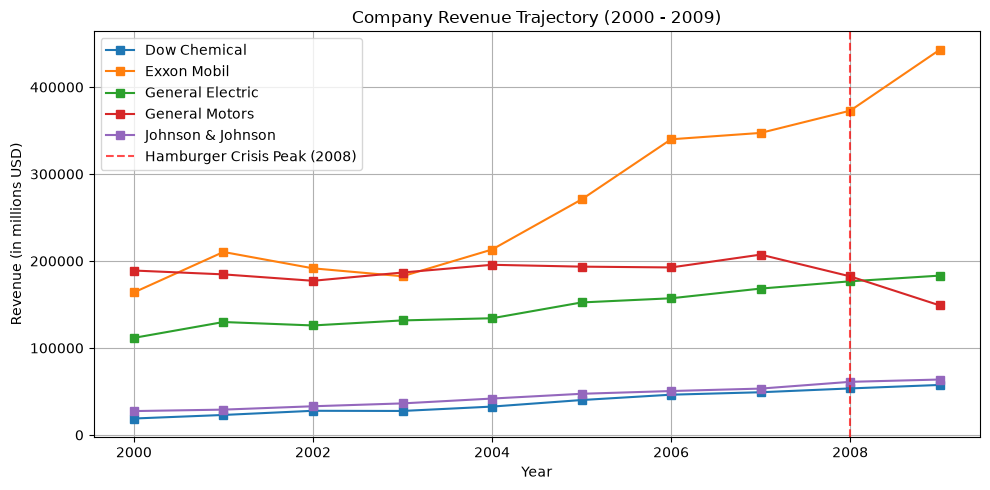

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. โหลดข้อมูลจากไฟล์ Excel
excel_file = r"d:\python1\No.1_Python.xlsx"
df = pd.read_excel(excel_file)

# 2. กรองข้อมูลเฉพาะปี 2000 - 2009 และสร้าง Pivot Table สำหรับรายได้ (Revenue)
df_recent = df[df["Year"] >= 2000].copy()
revenue_pivot = df_recent.pivot(
    index="Year", columns="Company", values="Revenue (in millions)"
)

# 3. พล็อตกราฟแนวโน้มรายได้
plt.figure(figsize=(10, 5))
for company in revenue_pivot.columns:
    plt.plot(
        revenue_pivot.index,
        revenue_pivot[company],
        marker="s",
        label=company,
    )

# 4. ตกแต่งรายละเอียดกราฟ
plt.title("Company Revenue Trajectory (2000 - 2009)")
plt.xlabel("Year")
plt.ylabel("Revenue (in millions USD)")
plt.axvline(
    x=2008,
    color="red",
    linestyle="--",
    alpha=0.7,
    label="Hamburger Crisis Peak (2008)",
)
plt.legend()
plt.grid(True)
plt.tight_layout()

# 5. เซฟเป็นไฟล์รูปภาพลงโฟลเดอร์
plt.savefig("revenue_chart.png", dpi=300)

# 6. แสดงหน้าต่างกราฟ
plt.show()

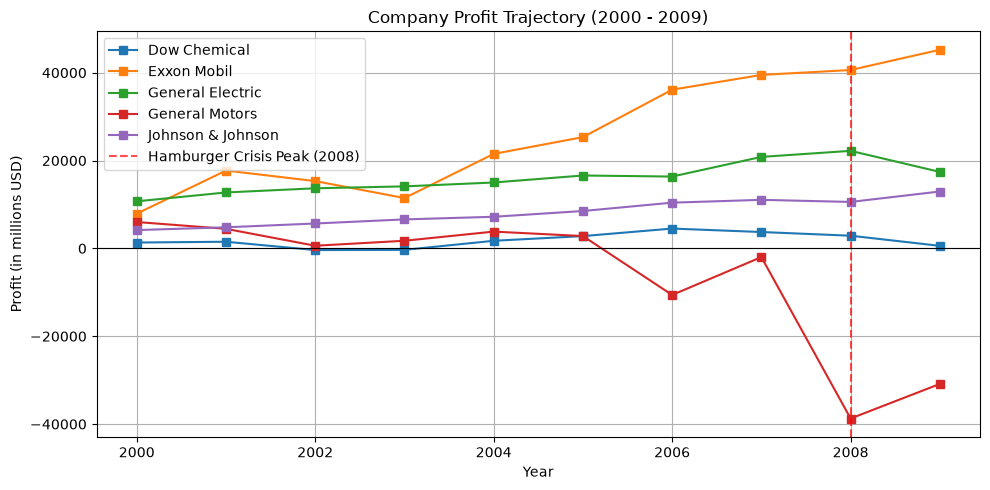

In [13]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. โหลดข้อมูลจากไฟล์ Excel
excel_file = r"d:\python1\No.1_Python.xlsx"
df = pd.read_excel(excel_file)

# 2. กรองข้อมูลเฉพาะปี 2000 - 2009 และสร้าง Pivot Table สำหรับกำไร (Profit)
df_recent = df[(df["Year"] >= 2000) & (df["Year"] <= 2009)].copy()
profit_pivot = df_recent.pivot(
    index="Year", columns="Company", values="Profit (in millions)"
)

# 3. พล็อตกราฟแนวโน้มกำไร
plt.figure(figsize=(10, 5))
for company in profit_pivot.columns:
    plt.plot(
        profit_pivot.index,
        profit_pivot[company],
        marker="s",
        label=company,
    )

# 4. ตกแต่งรายละเอียดกราฟ
plt.title("Company Profit Trajectory (2000 - 2009)")
plt.xlabel("Year")
plt.ylabel("Profit (in millions USD)")
plt.axvline(
    x=2008,
    color="red",
    linestyle="--",
    alpha=0.7,
    label="Hamburger Crisis Peak (2008)",
)
plt.axhline(y=0, color="black", linewidth=0.8)  # เส้นศูนย์ เผื่อบริษัทที่ขาดทุน
plt.legend()
plt.grid(True)
plt.tight_layout()

# 5. เซฟเป็นไฟล์รูปภาพ
plt.savefig("profit_chart.png", dpi=300)

# 6. แสดงหน้าต่างกราฟ
plt.show()